# Machine Learning – Assignment 2
**Classification of handwritten capital letters (UCI Letter Recognition)**

Name: Karthikeyan  |  BITS ID: 2025NS04128  |  Programme: M.Tech (Data Science & Engineering)

This notebook implements the five classifiers required by the assignment on one multi-class dataset, evaluates them with the six required metrics
(Accuracy, AUC, Precision, Recall, F1, MCC) and produces the comparison table used in the README and the Streamlit app.
It is meant to be run top-to-bottom on the BITS Virtual Lab (one screenshot of the executed notebook is part of the submission).

## 1. Imports and settings

In [1]:
import warnings, json, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, classification_report)

SEED = 42
TARGET = "letter"
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

## 2. Dataset
**UCI Machine Learning Repository – Letter Recognition** (Frey & Slate, 1991).
Each row describes one black-and-white rectangular pixel display of a capital letter (A–Z) rendered in one of 20 different fonts and randomly distorted.
The 16 numeric features are statistical moments / edge counts of the image, scaled to integers 0–15.

* Instances: 20,000  | Features: 16 (all integer) | Target: `letter` (26 classes)

Set `DATA_PATH` to wherever `letterdata.csv` is stored (on the Virtual Lab, upload it next to the notebook).

In [ ]:
# DATA_PATH = "Downloads/letterdata.csv"
# import os
# if not os.path.exists(DATA_PATH) and os.path.exists("../data/letterdata.csv"):
#     DATA_PATH = "../data/letterdata.csv"
raw = pd.read_csv("letterdata.csv")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (20000, 17)


,letter,xbox,ybox,width,height,onpix,xbar,ybar,x2bar,y2bar,xybar,x2ybar,xy2bar,xedge,xedgey,yedge,yedgex
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10


### 2.1 Quality checks and cleaning

In [7]:
print("Missing values:", int(raw.isna().sum().sum()))
dups = int(raw.duplicated().sum())
print("Exact duplicate rows:", dups)
df = raw.drop_duplicates().reset_index(drop=True)      # duplicates would leak between train and test
print("Shape after removing duplicates:", df.shape, "-> features:", df.shape[1] - 1, "| classes:", df[TARGET].nunique())
df.describe().T.round(2)

Missing values: 0
Exact duplicate rows: 1332
Shape after removing duplicates: (18668, 17) -> features: 16 | classes: 26


,count,mean,std,min,25%,50%,75%,max
xbox,18668.0,4.15,1.88,0.0,3.0,4.0,5.0,15.0
ybox,18668.0,7.24,3.19,0.0,5.0,8.0,10.0,15.0
width,18668.0,5.28,1.93,0.0,4.0,5.0,6.0,15.0
height,18668.0,5.51,2.18,0.0,4.0,6.0,7.0,15.0
onpix,18668.0,3.66,2.16,0.0,2.0,3.0,5.0,15.0
xbar,18668.0,6.92,2.03,0.0,6.0,7.0,8.0,15.0
ybar,18668.0,7.53,2.32,0.0,6.0,7.0,9.0,15.0
x2bar,18668.0,4.58,2.63,0.0,3.0,4.0,6.0,15.0
y2bar,18668.0,5.20,2.32,0.0,4.0,5.0,7.0,15.0
xybar,18668.0,8.35,2.47,0.0,7.0,8.0,10.0,15.0


### 2.2 Exploratory plots

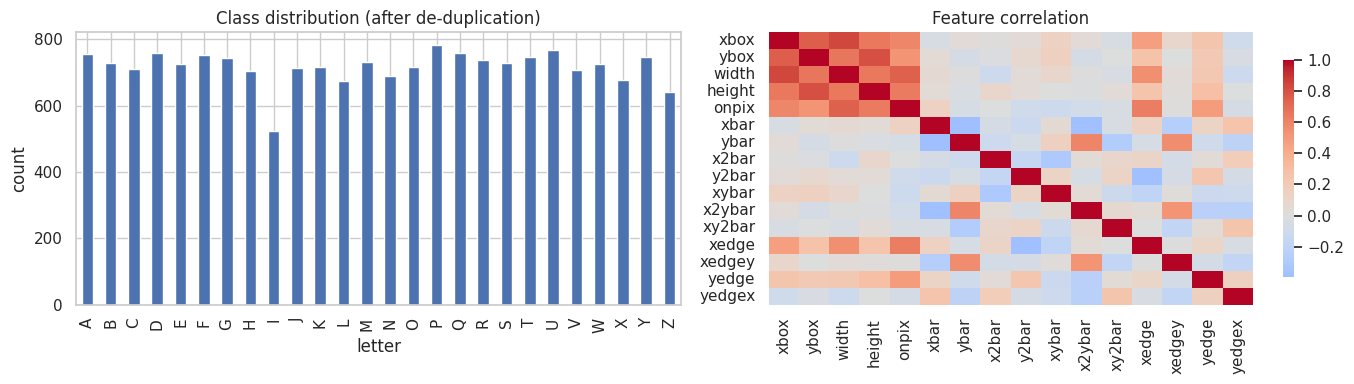

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df[TARGET].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="#4c72b0")
ax[0].set_title("Class distribution (after de-duplication)"); ax[0].set_xlabel("letter"); ax[0].set_ylabel("count")
corr = df.drop(columns=TARGET).corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax[1], cbar_kws={"shrink": .8})
ax[1].set_title("Feature correlation")
plt.tight_layout(); plt.show()

The classes are almost perfectly balanced (about 520-780 rows per letter), so plain accuracy is a fair headline number, but we still report
macro-averaged metrics because this is a 26-class problem.

## 3. Train / test split
80 % / 20 % **stratified** split with a fixed seed. The test set is *only* used for the final evaluation; all hyper-parameter tuning below is done
with cross-validation inside the training set.

In [14]:
features = [c for c in df.columns if c != TARGET]
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=SEED)
X_train, y_train = train_df[features], train_df[TARGET]
X_test,  y_test  = test_df[features],  test_df[TARGET]
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (14934, 16)  Test: (3734, 16)


## 4. Metric function
The target has 26 classes, so the binary definitions are extended as follows:

* **Accuracy** – fraction of correct predictions.
* **AUC** – one-vs-rest ROC-AUC, macro-averaged over the 26 classes (needs predicted probabilities).
* **Precision / Recall / F1** – macro averages (every letter has the same weight).
* **MCC** – scikit-learn's multi-class Matthews correlation coefficient.

In [17]:
def compute_metrics(y_true, y_pred, y_proba, classes):
    y_true = np.asarray(y_true); classes = np.asarray(classes)
    present = [c for c in classes if c in set(y_true)]
    auc = np.nan
    if len(present) >= 2:
        cols = [int(np.where(classes == c)[0][0]) for c in present]
        p = y_proba[:, cols]; p = p / p.sum(axis=1, keepdims=True)
        auc = roc_auc_score(y_true, p, multi_class="ovr", average="macro", labels=present)
    return {"Accuracy": accuracy_score(y_true, y_pred), "AUC": auc,
            "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "Recall":    recall_score(y_true, y_pred, average="macro", zero_division=0),
            "F1":        f1_score(y_true, y_pred, average="macro", zero_division=0),
            "MCC":       matthews_corrcoef(y_true, y_pred)}

## 5. Hyper-parameter selection (training data only)
Only the two models that have an obvious knob get a small search: **k** for kNN and **C** for the RBF-SVM (3-fold stratified CV on the training split).
Logistic Regression, Decision Tree and Naive Bayes use their defaults on purpose, so the comparison shows "out-of-the-box" behaviour.

In [20]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
knn_cv = {}
for k in (1, 3, 5, 7, 9, 11):
    m = Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=k))])
    knn_cv[k] = cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1).mean()
svm_cv = {}
for c in (1.0, 10.0, 30.0):
    m = Pipeline([("scale", StandardScaler()), ("clf", SVC(kernel="rbf", C=c, gamma="scale"))])
    svm_cv[c] = cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1).mean()
best_k = max(knn_cv, key=knn_cv.get); best_c = max(svm_cv, key=svm_cv.get)
print("kNN CV accuracy:", {k: round(float(v), 4) for k, v in knn_cv.items()}, "-> best k =", best_k)
print("SVM CV accuracy:", {k: round(float(v), 4) for k, v in svm_cv.items()}, "-> best C =", best_c)

/home/cloud/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/home/cloud/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/home/cloud/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/home/cloud/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/home/cloud/anaconda3/lib/python3.12/site-packages/pandas/core

kNN CV accuracy: {1: 0.9324, 3: 0.9253, 5: 0.9239, 7: 0.9184, 9: 0.9132, 11: 0.9099} -> best k = 1
SVM CV accuracy: {1.0: 0.925, 10.0: 0.961, 30.0: 0.9616} -> best C = 30.0


## 6. Train the five models and evaluate on the test set

In [23]:
models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=3000, random_state=SEED))]),
    "Decision Tree":       Pipeline([("clf", DecisionTreeClassifier(random_state=SEED))]),
    "kNN":                 Pipeline([("scale", StandardScaler()),
                                     ("clf", KNeighborsClassifier(n_neighbors=best_k))]),
    "Naive Bayes":         Pipeline([("clf", GaussianNB())]),
    "Support Vector Machine": Pipeline([("scale", StandardScaler()),
                                     ("clf", SVC(kernel="rbf", C=best_c, gamma="scale", probability=True, random_state=SEED))]),
}
results, preds = {}, {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    results[name] = compute_metrics(y_test, preds[name], model.predict_proba(X_test), model.classes_)
    print(f"{name:24s} trained + evaluated in {time.time() - t0:5.1f}s")

Logistic Regression      trained + evaluated in   4.5s
Decision Tree            trained + evaluated in   0.3s
kNN                      trained + evaluated in   0.7s
Naive Bayes              trained + evaluated in   0.2s
Support Vector Machine   trained + evaluated in  30.7s


### 6.1 Comparison table (the table that goes into the README)

In [26]:
summary = pd.DataFrame(results).T.round(4)
summary.index.name = "ML Model Name"
summary

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7633,0.9778,0.7663,0.7620,0.7626,0.7538
Decision Tree,0.8677,0.9309,0.8689,0.8672,0.8677,0.8624
kNN,0.9440,0.9708,0.9451,0.9439,0.9443,0.9418
Naive Bayes,0.6256,0.9554,0.6405,0.6246,0.6228,0.6114
Support Vector Machine,0.9692,0.9993,0.9702,0.9688,0.9693,0.9680


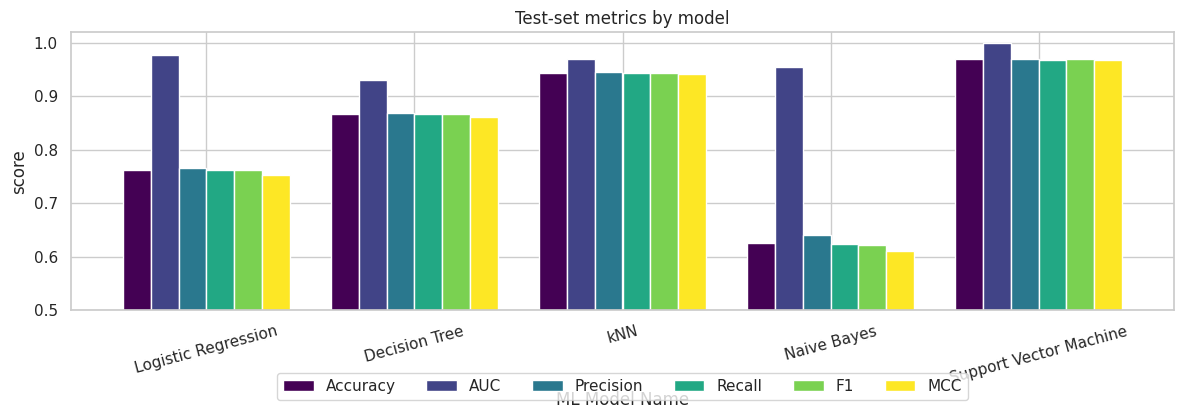

In [28]:
ax = summary.plot(kind="bar", figsize=(12, 4.5), width=.8, colormap="viridis")
ax.set_ylim(0.5, 1.02); ax.set_title("Test-set metrics by model"); ax.set_ylabel("score")
plt.xticks(rotation=15); plt.legend(ncol=6, loc="lower center", bbox_to_anchor=(.5, -.35)); plt.tight_layout(); plt.show()

## 7. Confusion matrices and classification reports

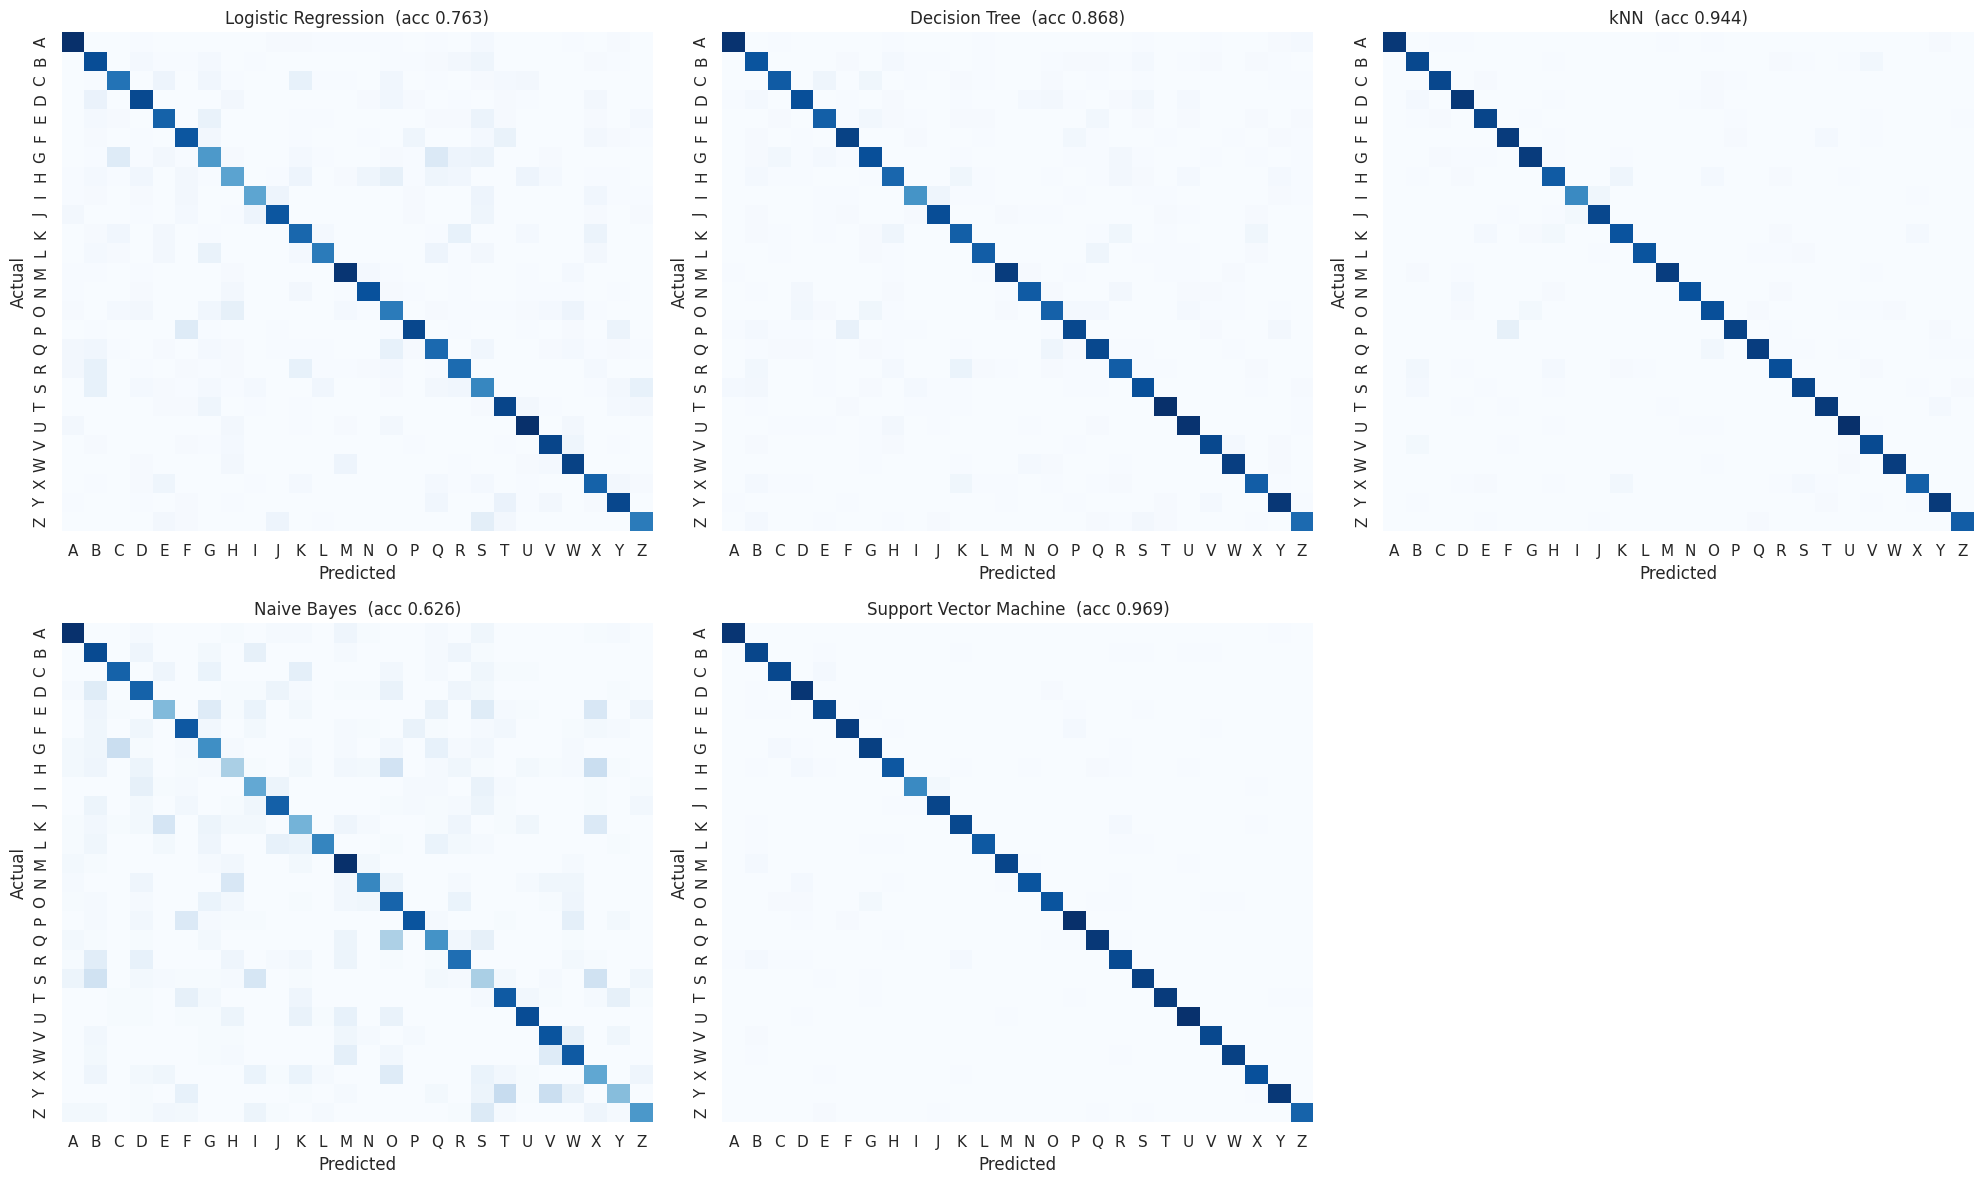

In [31]:
classes = list(models["Support Vector Machine"].classes_)
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, p, labels=classes)
    sns.heatmap(cm, ax=ax, cmap="Blues", cbar=False, xticklabels=classes, yticklabels=classes)
    ax.set_title(f"{name}  (acc {accuracy_score(y_test, p):.3f})"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [33]:
best_name = summary["MCC"].idxmax()
print("Best model by MCC:", best_name, "\n")
print(classification_report(y_test, preds[best_name], digits=3))

Best model by MCC: Support Vector Machine 

              precision    recall  f1-score   support

           A      0.993     0.993     0.993       151
           B      0.909     0.959     0.933       146
           C      0.952     0.979     0.965       142
           D      0.925     0.980     0.952       152
           E      0.940     0.966     0.952       145
           F      0.986     0.967     0.976       150
           G      0.947     0.966     0.957       149
           H      0.963     0.922     0.942       141
           I      0.990     0.952     0.971       105
           J      0.966     0.986     0.976       143
           K      0.959     0.965     0.962       144
           L      1.000     0.963     0.981       134
           M      0.986     0.966     0.976       146
           N      0.985     0.957     0.971       138
           O      0.978     0.917     0.946       144
           P      0.962     0.981     0.971       156
           Q      0.974     0.974    

### 7.1 Which letters does each model confuse most?

In [36]:
rows = []
for name, p in preds.items():
    cm = confusion_matrix(y_test, p, labels=classes).copy()
    np.fill_diagonal(cm, 0)
    order = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:3], cm.shape))[0]
    per_class_f1 = pd.Series(f1_score(y_test, p, average=None, labels=classes), index=classes)
    rows.append({"Model": name,
                 "Top confusions (actual -> predicted : count)": ", ".join(f"{classes[i]}->{classes[j]}:{cm[i, j]}" for i, j in order),
                 "Hardest letters (F1)": ", ".join(f"{k} {v:.2f}" for k, v in per_class_f1.nsmallest(3).items())})
pd.DataFrame(rows).set_index("Model")

,Top confusions (actual -> predicted : count),Hardest letters (F1)
Model,,
Logistic Regression,"G->Q:19, P->F:17, G->C:17","G 0.57, H 0.57, S 0.58"
Decision Tree,"P->F:11, R->K:9, Q->O:7","H 0.79, K 0.80, B 0.80"
kNN,"P->F:13, H->K:7, I->J:6","H 0.88, K 0.90, B 0.90"
Naive Bayes,"Q->O:42, Y->T:31, Y->V:29","S 0.30, H 0.36, X 0.44"
Support Vector Machine,"I->J:4, O->G:4, R->B:3","R 0.93, B 0.93, H 0.94"


## 8. Observations
The README contains the written observation for every model. In short (numbers are the table in section 6.1):

* **SVM (RBF)** is the clear winner – it is first in Accuracy, AUC, Precision, Recall, F1 and MCC.
* **kNN** is a strong second: with k = 1 it behaves like a nearest-font-template matcher, which suits this dataset (same 20 fonts appear in train and test),
  but k = 1 produces hard 0/1 probabilities, which is why its **AUC is lower than Logistic Regression's** even though its accuracy is much higher.
* **Decision Tree** is in the middle; **Logistic Regression** is limited by its linear boundaries; **Naive Bayes** is the weakest because the 16 features are strongly correlated and not Gaussian.

## 9. Save outputs (same files the repo uses)

In [31]:
import joblib, os
os.makedirs("model_out", exist_ok=True)
summary.to_csv("model_out/metrics_summary_notebook.csv")
test_df.to_csv("model_out/test_data_notebook.csv", index=False)
for name, model in models.items():
    joblib.dump(model, f"model_out/{name.lower().replace(' ', '_')}.joblib", compress=3)
print("Saved:", sorted(os.listdir("model_out")))

Saved: ['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'metrics_summary_notebook.csv', 'naive_bayes.joblib', 'support_vector_machine.joblib', 'test_data_notebook.csv']
